# IdSarcasm — replikasi di Google Colab

Notebook ini menjalankan fine-tuning baseline IndoBERT IndoNLU pada dataset Twitter Indonesia Sarcastic, mengikuti resep repo. Dataset diunduh otomatis dari Hugging Face. Runtime GPU direkomendasikan.

Untuk Reddit, ubah DATASET_NAME menjadi w11wo/reddit_indonesia_sarcastic dan TEXT_COLUMN menjadi text pada sel konfigurasi.

## 1. Pilih GPU
Di Colab, pilih **Runtime → Change runtime type → T4 GPU** (atau GPU lain yang tersedia).

In [1]:
import torch
print('PyTorch:', torch.__version__)
print('GPU tersedia:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Aktifkan GPU melalui Runtime → Change runtime type → T4 GPU.')

PyTorch: 2.11.0+cu130
GPU tersedia: True
GPU: Tesla T4


## 2. Clone repo dan pasang dependensi
Jalankan sekali setiap kali memulai runtime Colab yang baru.

In [ ]:
%cd /content
!git clone https://github.com/w11wo/id_sarcasm.git
%cd /content/id_sarcasm
!pip install -q -r requirements.txt "transformers==4.47.1" "huggingface_hub<1.0"

/content
Cloning into 'id_sarcasm'...
remote: Enumerating objects: 230, done.
remote: Counting objects: 100% (230/230), done.
remote: Compressing objects: 100% (134/134), done.
remote: Total 230 (delta 134), reused 182 (delta 90), pack-reused 0 (from 0)
Receiving objects: 100% (230/230), 1.32 MiB | 2.24 MiB/s, done.
Resolving deltas: 100% (134/134), done.
/content/id_sarcasm
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 100.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.

In [3]:
# Keep this cloned copy compatible with the installed scikit-learn and Transformers Trainer.
from pathlib import Path

script = Path("/content/id_sarcasm/scripts/run_classification.py")
source = script.read_text()

old_classes = "classes=classes, y="
new_classes = "classes=np.array(classes), y="
if old_classes in source:
    source = source.replace(old_classes, new_classes)
elif new_classes not in source:
    raise RuntimeError("Expected compute_class_weight call not found.")

old_loss = "def compute_loss(self, model, inputs, return_outputs=False):"
new_loss = "def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):"
if old_loss in source:
    source = source.replace(old_loss, new_loss)
elif new_loss not in source:
    raise RuntimeError("Expected WeightedTrainer.compute_loss method not found.")

script.write_text(source)
print("Compatibility fixes applied:")
print(next(line.strip() for line in source.splitlines() if "compute_class_weight(" in line))
print(next(line.strip() for line in source.splitlines() if "def compute_loss(" in line))

Compatibility fixes applied:
compute_class_weight(class_weight="balanced", classes=np.array(classes), y=train_dataset["label"])
def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):


## 3. Konfigurasi eksperimen
Default mengikuti baseline Twitter IndoBERT Base. Untuk uji singkat, turunkan EPOCHS ke 3; untuk resep repo, gunakan 100.

In [4]:
DATASET_NAME = 'w11wo/twitter_indonesia_sarcastic'
TEXT_COLUMN = 'tweet'
MODEL_NAME = 'indobenchmark/indobert-base-p1'
OUTPUT_DIR = '/content/drive/MyDrive/idsarcasm/indobert-twitter-retry'
EPOCHS = 100
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64

# Untuk Reddit, gunakan pasangan berikut:
# DATASET_NAME = 'w11wo/reddit_indonesia_sarcastic'
# TEXT_COLUMN = 'text'

# Untuk percobaan awal yang lebih cepat:
# EPOCHS = 3
# TRAIN_BATCH_SIZE = 16
# EVAL_BATCH_SIZE = 32

## 4. Hubungkan Google Drive
Output model, prediksi, dan log disimpan di Drive agar tidak hilang saat runtime Colab berhenti.

In [5]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## 5. Jalankan fine-tuning
Cell ini tidak mengunggah model ke Hugging Face. Waktu training bergantung pada GPU dan dataset; 100 epoch dapat memerlukan waktu cukup lama.

In [6]:
import subprocess
from pathlib import Path

# Apply compatibility fixes even if the earlier setup cell was skipped.
script = Path('/content/id_sarcasm/scripts/run_classification.py')
script_source = script.read_text()
old_classes = 'classes=classes, y='
new_classes = 'classes=np.array(classes), y='
if old_classes in script_source:
    script_source = script_source.replace(old_classes, new_classes)
elif new_classes not in script_source:
    raise RuntimeError('Expected compute_class_weight call not found; refusing to start.')
old_loss = 'def compute_loss(self, model, inputs, return_outputs=False):'
new_loss = 'def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):'
if old_loss in script_source:
    script_source = script_source.replace(old_loss, new_loss)
elif new_loss not in script_source:
    raise RuntimeError('Expected WeightedTrainer.compute_loss method not found; refusing to start.')
script.write_text(script_source)
print('Verified:', next(line.strip() for line in script_source.splitlines() if 'compute_class_weight(' in line))
print('Verified:', next(line.strip() for line in script_source.splitlines() if 'def compute_loss(' in line))
command = [
    'python', 'scripts/run_classification.py',
    '--model_name_or_path', MODEL_NAME,
    '--dataset_name', DATASET_NAME,
    '--dataset_config_name', 'default',
    '--shuffle_train_dataset',
    '--metric_name', 'f1',
    '--text_column_names', TEXT_COLUMN,
    '--label_column_name', 'label',
    '--max_seq_length', '128',
    '--per_device_train_batch_size', str(TRAIN_BATCH_SIZE),
    '--per_device_eval_batch_size', str(EVAL_BATCH_SIZE),
    '--learning_rate', '1e-5',
    '--lr_scheduler_type', 'cosine',
    '--weight_decay', '0.03',
    '--label_smoothing_factor', '0.0',
    '--num_train_epochs', str(EPOCHS),
    '--do_train', '--do_eval', '--do_predict',
    '--output_dir', OUTPUT_DIR,
    '--save_strategy', 'epoch',
    '--evaluation_strategy', 'epoch',
    '--logging_strategy', 'epoch',
    '--load_best_model_at_end',
    '--metric_for_best_model', 'f1',
    '--seed', '42',
    '--report_to', 'none',
    '--fp16',
]
print('Menjalankan:', ' '.join(command))
process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in process.stdout:
    print(line, end="")
return_code = process.wait()
if return_code != 0:
    raise subprocess.CalledProcessError(return_code, command)

Verified: compute_class_weight(class_weight="balanced", classes=np.array(classes), y=train_dataset["label"])
Verified: def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
Menjalankan: python scripts/run_classification.py --model_name_or_path indobenchmark/indobert-base-p1 --dataset_name w11wo/twitter_indonesia_sarcastic --dataset_config_name default --shuffle_train_dataset --metric_name f1 --text_column_names tweet --label_column_name label --max_seq_length 128 --per_device_train_batch_size 32 --per_device_eval_batch_size 64 --learning_rate 1e-5 --lr_scheduler_type cosine --weight_decay 0.03 --label_smoothing_factor 0.0 --num_train_epochs 100 --do_train --do_eval --do_predict --output_dir /content/drive/MyDrive/idsarcasm/indobert-twitter-retry --save_strategy epoch --evaluation_strategy epoch --logging_strategy epoch --load_best_model_at_end --metric_for_best_model f1 --seed 42 --report_to none --fp16
I0000 00:00:1791610267.930577    4168 cpu_feature_g

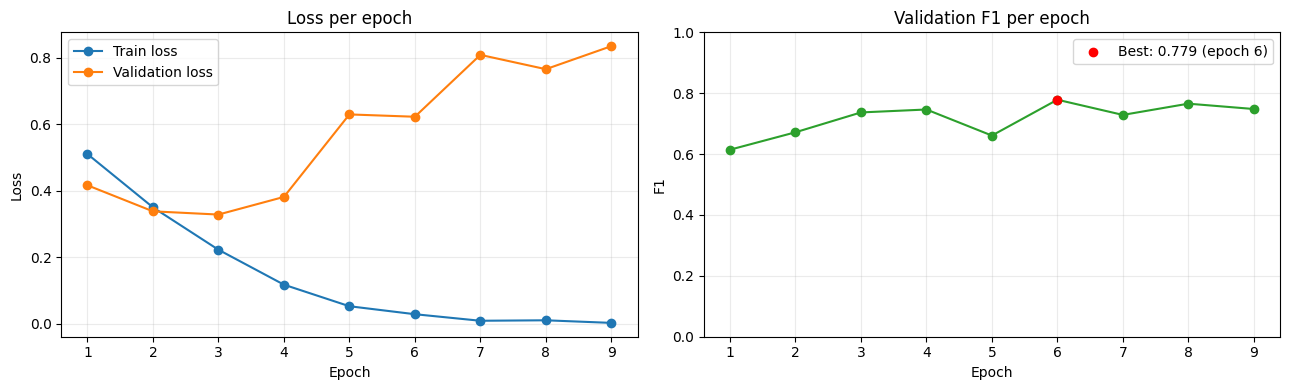

Metrik test:
  accuracy: 0.8903
  f1: 0.7611
  precision: 0.8319
  recall: 0.7015


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


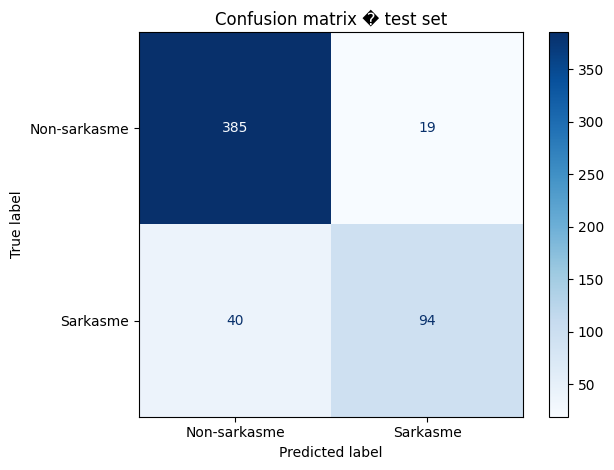

In [9]:
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Kurva training dari log Trainer.
output_dir = Path(OUTPUT_DIR)
state = json.loads((output_dir / "trainer_state.json").read_text())
history = state.get("log_history", [])

train_loss = [(row["epoch"], row["loss"]) for row in history if "loss" in row and "epoch" in row]
valid_loss = [(row["epoch"], row["eval_loss"]) for row in history if "eval_loss" in row and "epoch" in row]
valid_f1 = [(row["epoch"], row["eval_f1"]) for row in history if "eval_f1" in row and "epoch" in row]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if train_loss:
    axes[0].plot(*zip(*train_loss), marker="o", label="Train loss")
if valid_loss:
    axes[0].plot(*zip(*valid_loss), marker="o", label="Validation loss")
axes[0].set(title="Loss per epoch", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=0.25)
axes[0].legend()

if valid_f1:
    axes[1].plot(*zip(*valid_f1), marker="o", color="tab:green")
    best_epoch, best_f1 = max(valid_f1, key=lambda point: point[1])
    axes[1].scatter([best_epoch], [best_f1], color="red", zorder=3, label=f"Best: {best_f1:.3f} (epoch {best_epoch:g})")
    axes[1].legend()
axes[1].set(title="Validation F1 per epoch", xlabel="Epoch", ylabel="F1", ylim=(0, 1))
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Ringkasan metrik evaluasi test yang disimpan oleh script.
metrics_path = output_dir / "eval_results.json"
if metrics_path.exists():
    test_metrics = json.loads(metrics_path.read_text())
    metric_names = ("eval_accuracy", "eval_f1", "eval_precision", "eval_recall")
    print("Metrik test:")
    for name in metric_names:
        if name in test_metrics:
            print(f"  {name.removeprefix('eval_')}: {test_metrics[name]:.4f}")

# Confusion matrix: prediksi tersimpan dalam TSV dan label diambil dari split test.
predictions_path = output_dir / "predict_results.txt"
with predictions_path.open(newline="") as file:
    predictions = [int(row["prediction"]) for row in csv.DictReader(file, delimiter="\t")]
test_dataset = load_dataset(DATASET_NAME, "default")["test"]
true_labels = [int(label) for label in test_dataset["label"]]
if len(predictions) != len(true_labels):
    raise ValueError(f"Jumlah prediksi ({len(predictions)}) tidak sama dengan jumlah label test ({len(true_labels)}).")

matrix = confusion_matrix(true_labels, predictions, labels=[0, 1])
ConfusionMatrixDisplay(matrix, display_labels=["Non-sarkasme", "Sarkasme"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix � test set")
plt.tight_layout()
plt.show()

## Hasil
File hasil tersimpan di MyDrive/idsarcasm/indobert-twitter-retry. Untuk mereplikasi model lain, ganti MODEL_NAME dan parameter mengikuti skrip yang sesuai di folder recipes/.

In [12]:
from pathlib import Path

output_dir = Path(OUTPUT_DIR)
if not output_dir.exists():
    raise FileNotFoundError(f"Folder output belum ditemukan: {output_dir}. Jalankan training terlebih dahulu.")

files = sorted(path for path in output_dir.rglob("*") if path.is_file())
total_bytes = sum(path.stat().st_size for path in files)

print(f"Folder: {output_dir.resolve()}")
print(f"Jumlah file: {len(files)} | Total ukuran: {total_bytes / (1024 ** 2):.2f} MB")
print()
print(f"{'Nama file':<40} | {'Path lengkap'}")
print("-" * 120)
for path in files:
    size_mb = path.stat().st_size / (1024 ** 2)
    print(f"{path.name:<40} | {path.resolve()} ({size_mb:.3f} MB)")

Folder: /content/drive/MyDrive/idsarcasm/indobert-twitter-retry
Jumlah file: 112 | Total ukuran: 13302.82 MB

Nama file                                | Path lengkap
------------------------------------------------------------------------------------------------------------------------
README.md                                | /content/drive/MyDrive/idsarcasm/indobert-twitter-retry/README.md (0.002 MB)
all_results.json                         | /content/drive/MyDrive/idsarcasm/indobert-twitter-retry/all_results.json (0.001 MB)
config.json                              | /content/drive/MyDrive/idsarcasm/indobert-twitter-retry/checkpoint-118/config.json (0.001 MB)
model.safetensors                        | /content/drive/MyDrive/idsarcasm/indobert-twitter-retry/checkpoint-118/model.safetensors (474.734 MB)
optimizer.pt                             | /content/drive/MyDrive/idsarcasm/indobert-twitter-retry/checkpoint-118/optimizer.pt (949.585 MB)
rng_state.pth                            | /